In [1]:
#电商经营情况分析

In [2]:
# 一、数据来源
# https://www.kaggle.com

In [3]:
# 二、数据说明
# 本次分析用的数据信息包括：
# 'order_id' 订单ID
# 'order_date' 订单日期
# 'order_status' 订单状态：已完成、待定、取消、退款
# 'sales_channel' 销售渠道
# 'customer_id' 客户ID
# 'customer_age' 客户年龄
# 'gender' 性别
# 'region' 地区
# 'shipping_method' 运输方式
# 'shipping_cost' 运费
# 'gross_sales' 总销售额
# 'discount_amount' 折扣金额
# 'net_sales' 净销售额
# '利润' 利润
# 'profit_margin_percentage' 利润率

In [4]:
# 三、问题描述
# 1、整体经营情况分析
# 2、不同地区经营情况分析
# 3、不同渠道经营情况分析
# 4、不同年龄群体消费情况分析
# 5、折扣敏感度分析
# 6、分析运费对成交的影响

In [5]:
# 四、使用工具
# python、 pandas、 seaborn等

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.sans-serif'] = ['SamHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

In [7]:
path = r'E:\BaiduSyncdisk\数据分析\kaggle案例\003customer_master\archive\ecommerce_sales_customer_analytics_150k.csv'
df = pd.read_csv(path)
print(df.head())
print("\n" + "-" * 60 + "\n")
#经检查，该组数据的总销售额（gross_sales）扣除了税款和运费成本，净销售额未扣税。
#数据中，gross_sales + tax_amount + shipping_cost - discount_amount = net_sales 。说明商品价格里包含了运输费。

     order_id  order_date order_time order_status sales_channel  customer_id  \
0  ORD-301242  2023-11-06   16:37:47    Completed    Mobile App  CUST-003102   
1  ORD-773460  2025-12-24   01:22:36    Completed       Website  CUST-003124   
2  ORD-449374  2021-07-05   14:24:21    Completed    Mobile App  CUST-012496   
3  ORD-567636  2023-01-21   07:20:26    Completed  Social Media  CUST-023928   
4  ORD-820028  2022-05-13   09:46:21    Completed  Social Media  CUST-012730   

    customer_name  customer_age  gender customer_segment  ... discount_amount  \
0    Jasmine Ryan            55    Male         Consumer  ...          477.89   
1     Scott Chase            26    Male          Premium  ...         1456.06   
2    Marc Wheeler            69  Female          Premium  ...           97.30   
3  Jennifer Smith            65    Male         Consumer  ...           53.34   
4    Jessica Wang            34  Female         Consumer  ...          133.63   

  tax_amount shipping_cost net_s

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  str    
 1   order_date                138116 non-null  str    
 2   order_time                138116 non-null  str    
 3   order_status              138116 non-null  str    
 4   sales_channel             138116 non-null  str    
 5   customer_id               138116 non-null  str    
 6   customer_name             138116 non-null  str    
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  str    
 9   customer_segment          138116 non-null  str    
 10  customer_type             138116 non-null  str    
 11  customer_city             138116 non-null  str    
 12  customer_state            138116 non-null  str    
 13  customer_country          138116 non-null  str    
 14 

In [9]:
print(df.describe())
print('/n' + '-'*60 +'/n')

        customer_age  customer_postal_code  delivery_days  \
count  138116.000000         138116.000000  113559.000000   
mean       45.862681          50210.889310       4.557772   
std        16.467676          28569.767779       2.810012   
min        18.000000            516.000000       0.000000   
25%        32.000000          25509.000000       2.000000   
50%        46.000000          50183.000000       4.000000   
75%        60.000000          74898.000000       7.000000   
max        74.000000          99950.000000      14.000000   

       estimated_delivery_days  customer_rating  loyalty_points_earned  \
count            113559.000000    113559.000000          138116.000000   
mean                  4.298875         3.677015             103.991051   
std                   2.594080         0.483672             115.175640   
min                   0.000000         1.600000               0.000000   
25%                   2.000000         3.400000              17.000000   
50%   

In [25]:
df.isna().sum()
#有缺失的数据，但相关信息对此次分析没有影响。

order_id                         0
order_date                       0
order_time                       0
order_status                     0
sales_channel                    0
customer_id                      0
customer_name                    0
customer_age                     0
gender                           0
customer_segment                 0
customer_type                    0
customer_city                    0
customer_state                   0
customer_country                 0
region                           0
customer_postal_code             0
payment_method                   0
payment_status                   0
currency                         0
shipping_method                  0
warehouse                        0
delivery_days                24557
estimated_delivery_days      24557
delivery_status                  0
return_status               128654
return_reason               128654
customer_rating              24557
review_sentiment             24557
customer_review     

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
#查看str列的值有没有异常
str_columns = df.select_dtypes(include = 'string').columns
for j in str_columns:
    print(f'{j}列')
    print(f'共有：{len(df[j].unique())}''个不同数据。')
    print(f'分别是: {df[j].unique()}')
    print('-' * 60)

order_id列
共有：138116个不同数据。
分别是: <StringArray>
['ORD-301242', 'ORD-773460', 'ORD-449374', 'ORD-567636', 'ORD-820028',
 'ORD-208728', 'ORD-686230', 'ORD-480470', 'ORD-417329', 'ORD-961581',
 ...
 'ORD-760069', 'ORD-772398', 'ORD-822730', 'ORD-712483', 'ORD-874457',
 'ORD-481534', 'ORD-487614', 'ORD-248062', 'ORD-252033', 'ORD-528577']
Length: 138116, dtype: str
------------------------------------------------------------
order_date列
共有：1826个不同数据。
分别是: <StringArray>
['2023-11-06', '2025-12-24', '2021-07-05', '2023-01-21', '2022-05-13',
 '2021-02-10', '2021-05-03', '2022-10-13', '2022-12-06', '2023-09-19',
 ...
 '2024-04-07', '2021-07-29', '2025-01-30', '2025-04-02', '2024-03-11',
 '2023-02-24', '2023-04-06', '2023-03-31', '2022-07-20', '2025-04-03']
Length: 1826, dtype: str
------------------------------------------------------------
order_time列
共有：68991个不同数据。
分别是: <StringArray>
['16:37:47', '01:22:36', '14:24:21', '07:20:26', '09:46:21', '10:05:47',
 '02:55:44', '21:19:50', '17:22:52', '1

In [13]:
#一、整体经营情况
#1、总净销售额、总利润、整体利润率
#2、总订单数、客单价、平均折扣
#3、按月度趋势：销售额、利润、利润率走势

In [14]:
#1、订单日期处理
df['order_date'] = pd.to_datetime(df['order_date'])
df['order_time'] = pd.to_datetime(df['order_time'], format = 'mixed')
df['year'] = df['order_date'].dt.year

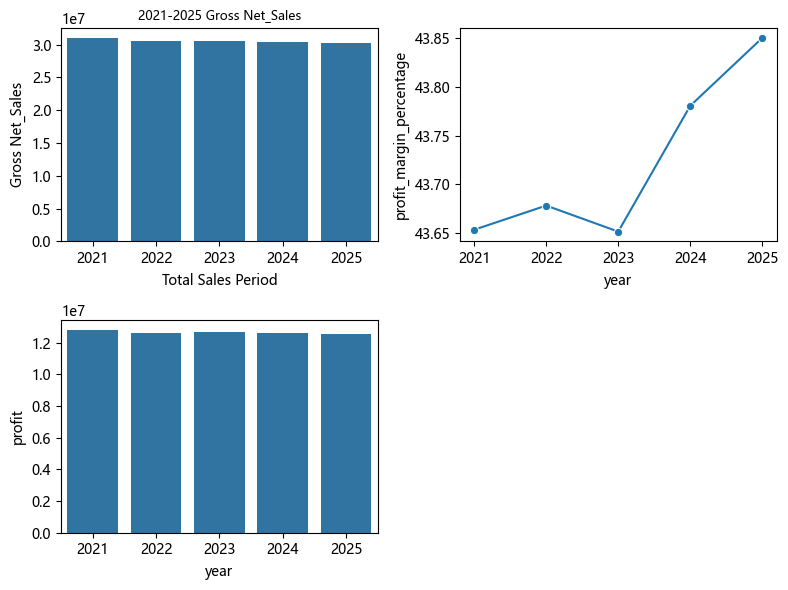

In [54]:
# 11、绘制条形图查看 --- >年度 总净销售额、总利润、整体利润率

#求出有效销售额，剔除取消订单和退货部分
efficient_df = df.query("order_status not in ['Cancelled', 'Returned']")
#fig,ax = plt.subplots(2, 2, figsize = (9, 6))
plt.figure(figsize = (8, 6))

#11、总净销售额
ax1 = plt.subplot2grid((2, 2), (0, 0))
sns.barplot(data = efficient_df,
            x = 'year',
            y = 'net_sales',
            ax = ax1,
            estimator = 'sum',
            errorbar = None
           )
ax1.set_xlabel('Total Sales Period')
ax1.set_ylabel('Gross Net_Sales')
ax1.set_title('2021-2025 Gross Net_Sales', fontsize = 9)

#12、总利润
ax3 = plt.subplot2grid((2, 2), (1, 0))
sns.barplot(data = efficient_df,
            x = 'year', 
            y = 'profit',
            ax = ax3,
            estimator = 'sum',
            errorbar = None
           )

#13、利润率
ax2 = plt.subplot2grid((2, 2), (0, 1))
sns.lineplot(data = efficient_df,
             x = 'year',
             y = 'profit_margin_percentage',
             ax = ax2,
             errorbar = None,
             marker = 'o'
            )

plt.tight_layout()
plt.show()
#各样本年度的总体净销售额差异不大，总体净利润率逐年有上升，但幅度不大，基本一致。

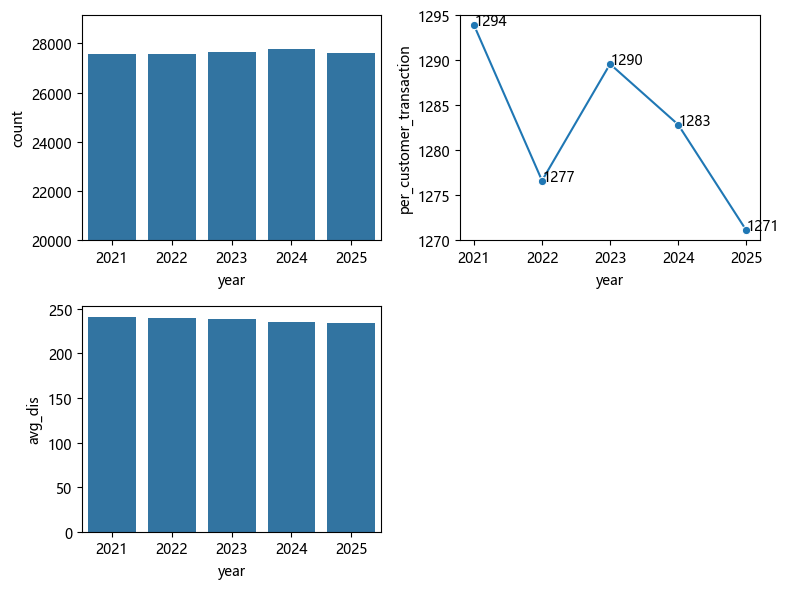

,year,dis,ct,avg_dis
0,2021,6637452.44,27554,240.89
1,2022,6613153.09,27564,239.92
2,2023,6584731.05,27632,238.30
3,2024,6525341.36,27768,235.00
4,2025,6458668.88,27598,234.03


In [37]:
#12、总订单数、客单价（净销售额/订单数）

plt.figure(figsize = (8, 6))
#1、总订单数
ax1 = plt.subplot2grid((2, 2), (0, 0))
sns.countplot(data = efficient_df,  
              x = 'year',
              ax = ax1
             )
ax1.set_ylim(bottom = 20000)

#2、客单价
gross_per_df = efficient_df.groupby(['customer_id', 'year']).agg(
    total_orders = ('order_id', 'count'),
    net_sales = ('net_sales', 'sum')
)
gross_per_df.reset_index(inplace = True)
gross_per_df['per_customer_transaction'] = round(gross_per_df['net_sales'] / gross_per_df['total_orders'], 2)
ax3 = plt.subplot2grid((2, 2), (0, 1))
sns.lineplot(data = gross_per_df,
             x = 'year',
             y = 'per_customer_transaction',
             ax = ax3,
             errorbar = None,
             marker = 'o'
            )
lines = ax3.get_lines()
x_list = []
y_list = []
for line in lines:
    x_list = line.get_xdata()
    y_list = line.get_ydata()

for x, y in zip(x_list, y_list):
    ax3.annotate(
        text = f'{y:.0f}',
        xy = (x, y),
        xytext = (12, 0),
        textcoords = 'offset points',
        ha = 'center'
    )   

#3、年度平均折扣额
avg_discount = efficient_df.groupby('year').agg(
    dis = ('discount_amount', 'sum'),
    ct = ('order_id', 'count')
).reset_index()
avg_discount['avg_dis'] = round(avg_discount['dis'] / avg_discount['ct'], 2)
ax4 = plt.subplot2grid((2, 2), (1, 0))
sns.barplot(data = avg_discount,
            x = 'year',
            y = 'avg_dis',
            ax = ax4,
            errorbar = None
           )

plt.tight_layout()
plt.show()
#各年度订单量变化不大，各年度平均折扣额逐年小幅降低，但客单价一直浮动明显，并且2023、2024、2025年逐年下降.
#初步分析各年度折扣活动折扣额的设置情况不同。

In [55]:
#13、按月/季度趋势：销售额、利润、利润率走势

#数据量过多，对数据按月重新采样
resample_df = efficient_df[['order_date', 'net_sales', 'discount_amount', 'profit', 'profit_margin_percentage']]
resample_df.set_index('order_date', inplace = True)

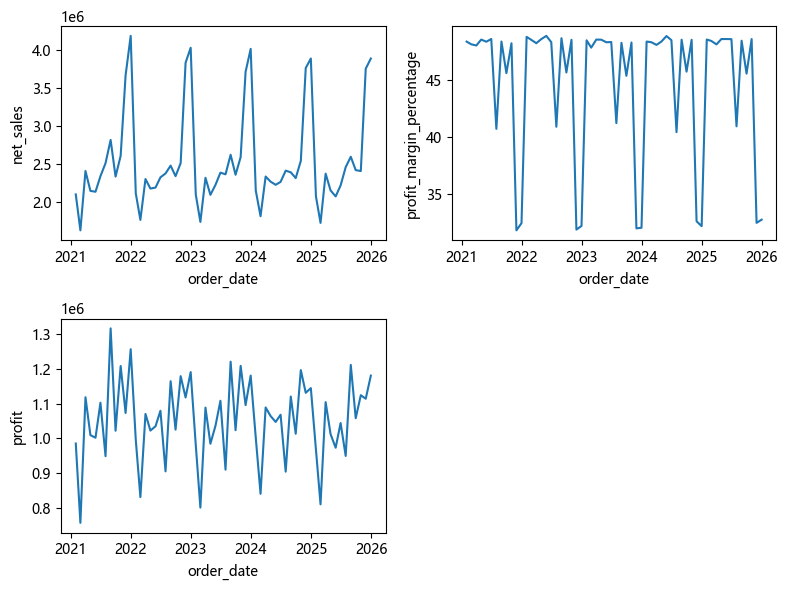

In [56]:
plt.figure(figsize = (8, 6))
ax1 = plt.subplot2grid((2, 2), (0, 0))
ax2 = plt.subplot2grid((2, 2), (0, 1))
ax3 = plt.subplot2grid((2, 2), (1, 0))

#绘制月度净销售额折线图。
monthly_df = resample_df.resample('ME')['net_sales', 'profit'].sum()
monthly_df = monthly_df.reset_index()
sns.lineplot(data = monthly_df,
             x = 'order_date',
             y = 'net_sales',
             ax = ax1,
             errorbar = None
            )

#月度利润趋势图
sns.lineplot(data = monthly_df,
             x = 'order_date',
             y = 'profit',
             ax = ax3,
             errorbar = None
            )

#利润率月度趋势图
monthly_profit_percentage = resample_df.resample('ME')['profit_margin_percentage'].mean()
monthly_profit_percentage = monthly_profit_percentage.reset_index()
sns.lineplot(data = monthly_profit_percentage,
             x = 'order_date',
             y = 'profit_margin_percentage',
             ax = ax2,
             errorbar = None
            )
plt.tight_layout()
plt.show()
#净销售额有明显的周期性，年初处于低位，年终相对平稳，年底大幅上升。
#净利润收入的变化基本与净销售额同步，但净销售额的上涨同步伴随着净利润率的下降，上涨幅度越大，净利润率下降越多。
#考虑进一步分析不同折扣率下对净销售额提升幅度的影响。

In [ ]:
#二、地区分析
#1、各地区 销售额 排名
#2、各地区利润、利润率、折扣额排名
#3、各地区利润率排名
#4、折扣额排名

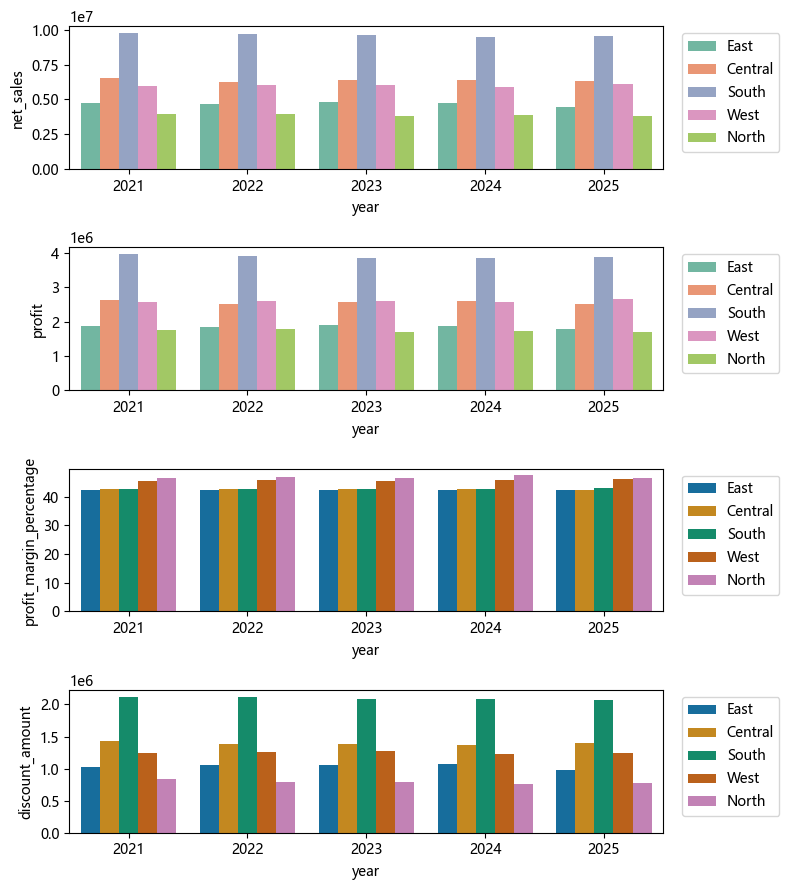

In [57]:
plt.figure(figsize = (8, 9))
ax1 = plt.subplot2grid((4, 1), (0, 0), colspan = 1)
ax2 = plt.subplot2grid((4, 1), (1, 0), colspan = 1)
ax3 = plt.subplot2grid((4, 1), (2, 0))
ax4 = plt.subplot2grid((4, 1), (3, 0))

#21、各地区 销售额 排名
sns.barplot(data = efficient_df,
             x = 'year',
             y = 'net_sales',
             hue = 'region',
             palette = 'Set2',
             ax = ax1,
             errorbar = None,
             estimator = 'sum',
            )
ax1.legend(loc = 'upper left', bbox_to_anchor = (1.02, 1))

#22、各地区利润、利润率、折扣额排名
sns.barplot(data = efficient_df,
            x = 'year',
            y = 'profit',
            hue = 'region',
            palette = 'Set2',
            errorbar = None,
            estimator = 'sum',
            ax = ax2
           )
ax2.legend(loc = 'upper left', bbox_to_anchor = (1.02, 1))

#23、利润率排名
sns.barplot(data = efficient_df,
            x = 'year',
            y = 'profit_margin_percentage',
            hue = 'region',
            palette = 'colorblind',
            errorbar = None,
            ax = ax3
           )
ax3.legend(loc = 'upper left', bbox_to_anchor = (1.02, 1))

#24、折扣额排名
sns.barplot(data = efficient_df,
            x = 'year',
            y = 'discount_amount',
            hue = 'region',
            palette = 'colorblind',
            errorbar = None,
            estimator = 'sum',
            ax = ax4
           )
ax4.legend(loc = 'upper left', bbox_to_anchor = (1.02, 1))
plt.tight_layout()
plt.show()
#南部虽然净销售额、利润额最高，但平均利润率相对不高，推测南部地区折扣活动较多或参与的消费人数较多。
#北部地区净销售额、利润额最低，但平均利润率最高，考虑为偏远地区，折扣活动覆盖不到。
#西部地区净销售额、利润额常年与中部持平，但利润率明显高于中部地区。
#东部地区各项指标常年处于低位，考虑销售渠道问题和物流问题。

In [79]:
#三、不同渠道经营情况分析
#1、各销售渠道带来的销售额、利润
#2、各渠道的利润率排名

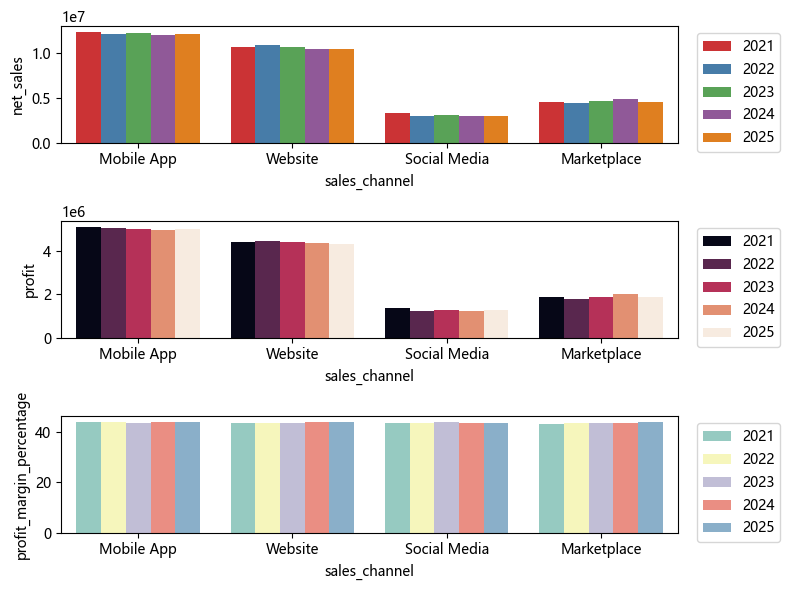

In [80]:
#31、各销售渠道带来的销售额

fig, axes = plt.subplots(3, 1, figsize = (8, 6))
sns.barplot(data = efficient_df,
            x = 'sales_channel',
            y = 'net_sales',
            hue = 'year',
            palette = 'Set1',
            errorbar = None,
            estimator = 'sum',
            ax = axes[0]
           )
axes[0].legend(loc = 'upper left', bbox_to_anchor = (1.02, 1))

#32、各销售渠道带来的利润
sns.barplot(data = efficient_df,
            x = 'sales_channel',
            y = 'profit',
            hue = 'year',
            palette = 'rocket',
            errorbar = None,
            estimator = 'sum',
            ax = axes[1]
           )
axes[1].legend(loc = 'upper left', bbox_to_anchor = (1.02, 1))

#33、各销售渠道的利润率
sns.barplot(data = efficient_df,
             x = 'sales_channel',
             y = 'profit_margin_percentage',
             hue = 'year',
            palette = 'Set3',
             errorbar = None,
            estimator = 'mean',
             ax = axes[2]
            )
axes[2].legend(loc = 'upper left', bbox_to_anchor = (1.02, 1))


plt.tight_layout()
plt.show()
#移动APP、网络商城的销售优势明显，贡献了大部分销售额.
#社交媒体渠道最低，按照一般经验，该渠道有待进一步开发。
#各渠道利润率基本一致，不存在优势区别，利润总额高低基本与净销售额成正比。
#推测折扣活动是面向全平台发布的，未采用差异化策略。

In [ ]:
#四、不同年龄群体消费情况分析
#年龄分布与消费能力：各年龄段销售额、客单价、利润率

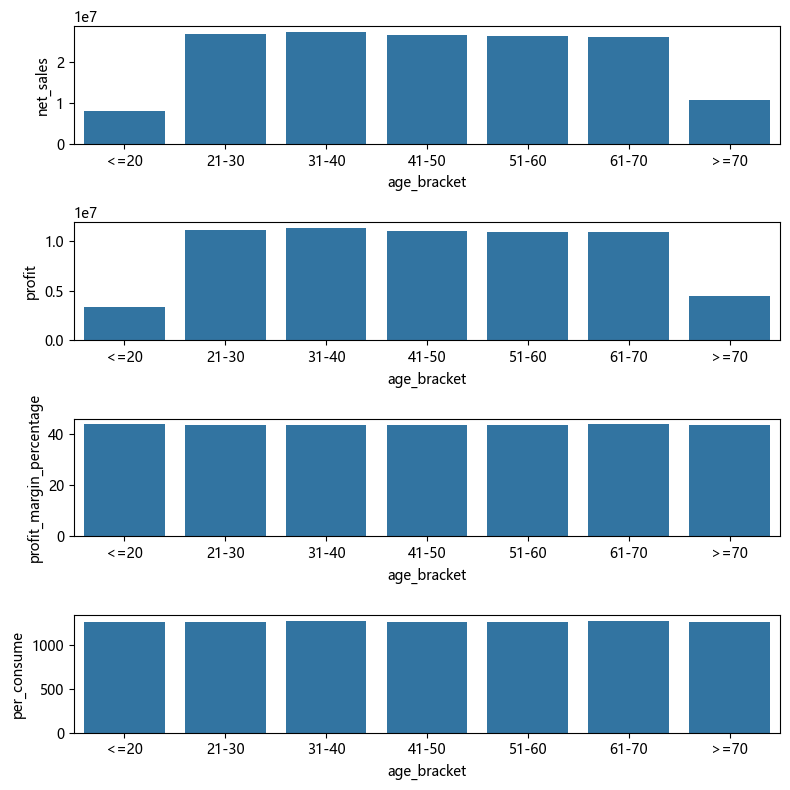

In [58]:
customer_df = efficient_df[['customer_age','customer_id', 'order_id', 'net_sales', 'profit', 'customer_order_count', 'profit_margin_percentage']]
age_bins = [0, 20, 30, 40, 50, 60, 70, 80]
age_labels = ['<=20', '21-30', '31-40', '41-50', '51-60', '61-70', '>=70']
customer_df['age_bracket'] = pd.cut(customer_df['customer_age'],
                          bins = age_bins,
                          labels = age_labels
                         )
plt.figure(figsize = (8, 8))
#41、各年龄段销售额
ax1 = plt.subplot2grid((4, 1), (0, 0))
sns.barplot(data = customer_df,
            x = 'age_bracket',
            y = 'net_sales',
            errorbar = None,
            estimator = 'sum',
            ax = ax1
           )

#42、各年龄段利润
ax2 = plt.subplot2grid((4, 1), (1, 0))
sns.barplot(data = customer_df,
            x = 'age_bracket',
            y = 'profit',
            errorbar = None,
            estimator = 'sum',
            ax = ax2
           )
#43、各年龄段利润率
ax3 = plt.subplot2grid((4,1), (2, 0))
sns.barplot(data = customer_df,
            x = 'age_bracket',
            y = 'profit_margin_percentage',
            errorbar = None,
            estimator = 'mean',
            ax = ax3
           )
#43、各年龄段客单价
per_df = customer_df.groupby(['customer_id', 'age_bracket']).agg(
    order_amounts = ('order_id', 'count'),
    net_sales = ('net_sales', 'sum')
)
per_df['per_consume'] = round(per_df['net_sales'] / per_df['order_amounts'], 2)
per_df.reset_index(inplace = True)
ax4 = plt.subplot2grid((4,1), (3, 0))
sns.barplot(data = per_df,
            x = 'age_bracket',
            y = 'per_consume',
            errorbar = None,
            estimator = 'mean',
            ax = ax4
           )

plt.tight_layout()
plt.show()
#排除"<=20"岁和“>=70"岁样本数量较少的影响，可以看出，各年龄段的消费力和客单价基本无差别。

In [ ]:
#五、折扣敏感度分析
#1、不同折扣率区间的利润表现，分析最佳折扣率区间
#2、哪些地区、渠道、年龄段对折扣敏感

In [59]:
discount_df = efficient_df[['order_date','order_id','gross_sales','region', 'customer_age', 'sales_channel', 
                  'profit', 'net_sales', 'discount_amount', 'profit_margin_percentage', 'shipping_cost', 'tax_amount']
    ]
#由于源数据中，gross_sales已经剔除了discount_amount和shipping_cost，而net_sales一项也没剔除，所以应统一数据口径。
discount_df['truthly_gross_sales'] = discount_df['gross_sales'] + discount_df['tax_amount'] + discount_df['shipping_cost']
discount_df['discount_percentage'] = round(100 * discount_df['discount_amount'] / discount_df['truthly_gross_sales'], 2)
discount_df = discount_df.set_index('order_date')

In [64]:
resample_discount = discount_df.resample('ME')['truthly_gross_sales', 'profit', 'net_sales', 'discount_amount'].sum()
resample_discount.reset_index(inplace = True)
resample_discount['month'] = resample_discount['order_date'].dt.month

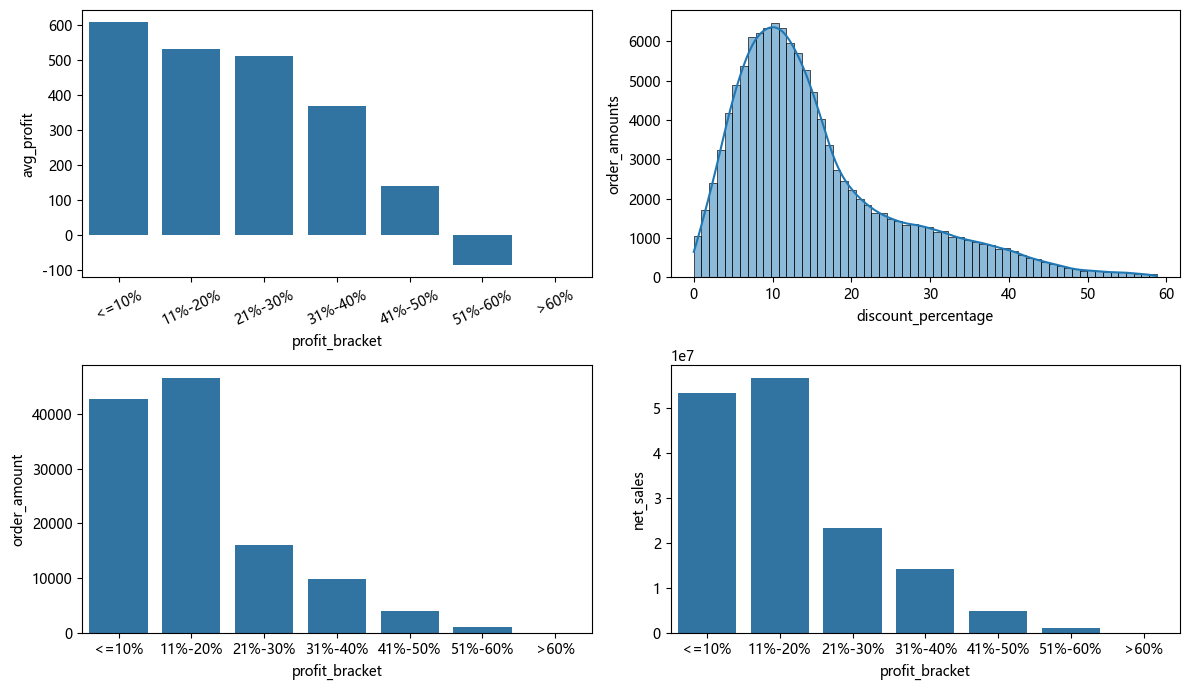

In [66]:
#51、不同折扣率区间的利润表现，分析最佳折扣率区间
profit_discount = discount_df.reset_index()
dis_bins = [0, 10, 20, 30, 40 , 50, 60, 70]
dis_labels = ['<=10%', '11%-20%', '21%-30%', '31%-40%', '41%-50%', '51%-60%', '>60%']
profit_discount['profit_bracket'] = pd.cut(profit_discount['discount_percentage'],
                                           bins = dis_bins,
                                           labels = dis_labels
                                          )
#绘制图表直观查看
#、不同折扣区间下的平均利润率
fig,ax = plt.subplots(2, 2, figsize = (12, 7))
sns.barplot(data = profit_discount,
            x = 'profit_bracket',
            y = 'profit',
            errorbar = None,
            estimator = 'mean',
            ax = ax[0, 0]
           )
ax[0, 0].tick_params(axis = 'x', rotation = 25)
ax[0, 0].set_ylabel('avg_profit')

#、促销活动设置的折扣率分布范围
sns.histplot(data = profit_discount,
             x = 'discount_percentage',
             bins = 60,
             ax = ax[0, 1],
             kde = True
            )
ax[0, 1].set_ylabel('order_amounts')

#、不同折扣率下的订单数量
sns.countplot(data = profit_discount,
            x = 'profit_bracket',
            ax = ax[1, 0]
           )
ax[1, 0].set_ylabel('order_amount')
#55、不同折扣率下的净销售额
sns.barplot(data = profit_discount,
            x = 'profit_bracket',
            y = 'net_sales',
            errorbar = None,
            estimator = 'sum',
            ax = ax[1, 1]
           )
ax[1, 1].set_ylabel('net_sales')

plt.tight_layout()
plt.show()

#可以看出，商品折扣率主要分布范围为0%—20%，且该范围内产生了最多的订单，实现了最高的净销售额。
#从图1来看，商品的临界折扣率在51%左右。折扣幅度超过这个临界就面临亏损。
#结合平均利润和净销售额来看，0%-20%是折扣最优区间，能同时保有高利润和高销量，建议重点维持该折扣段。
#但注意，11%-20%折扣率区间销售情况表现好的基础是，有长期保持的10%以下的折扣托底，
#如果11%-20%的折扣策略推行周期过于长，容易对10%以内的折扣策略造成挤压。

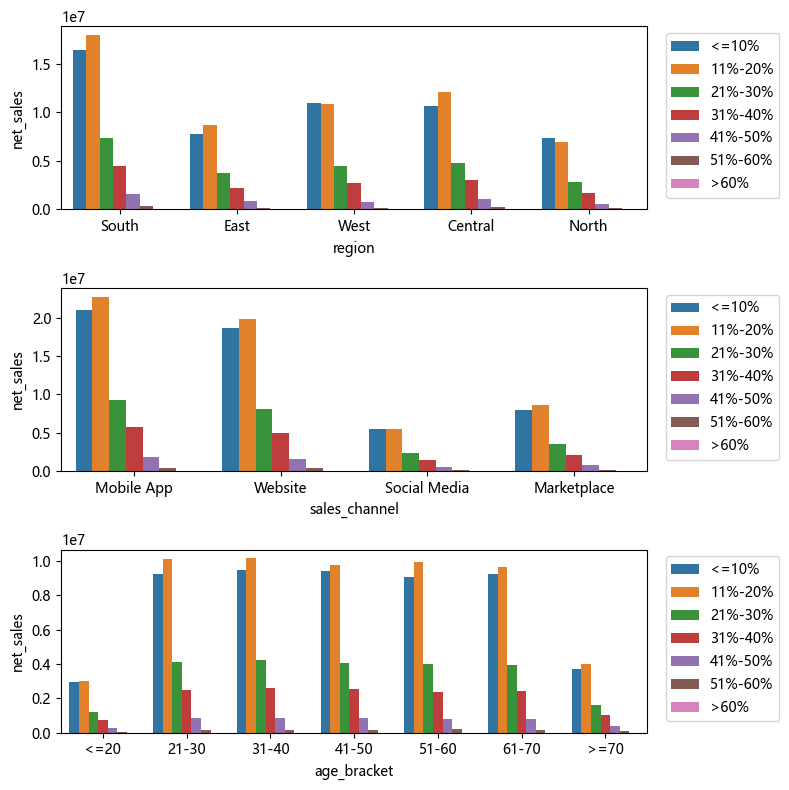

In [68]:
#53、哪些地区、渠道、年龄段对折扣敏感
fig, ax = plt.subplots(3, 1, figsize = (8, 8))
#1地区
sns.barplot(data = profit_discount,
            x = 'region',
            y = 'net_sales',
            hue = 'profit_bracket',
            errorbar = None,
            estimator = 'sum',
            ax = ax[0]
           )
ax[0].legend(loc = 'upper left', bbox_to_anchor = (1.02, 1))

#2渠道
sns.barplot(data = profit_discount,
            x = 'sales_channel',
            y = 'net_sales',
            hue = 'profit_bracket',
            errorbar = None,
            estimator = 'sum',
            ax = ax[1]
           )
ax[1].legend(loc = 'upper left', bbox_to_anchor = (1.02, 1))

#3、年龄段
age_bins = [0, 20, 30, 40, 50, 60, 70, 80]
age_labels = ['<=20', '21-30', '31-40', '41-50', '51-60', '61-70', '>=70']
profit_discount['age_bracket'] = pd.cut(
    profit_discount['customer_age'],
    bins = age_bins,
    labels = age_labels
)
sns.barplot(data = profit_discount,
            x = 'age_bracket',
            y = 'net_sales',
            hue = 'profit_bracket',
            errorbar = None,
            estimator ='sum',
            ax = ax[2]
           )
ax[2].legend(loc = 'upper left', bbox_to_anchor = (1.02, 1))

plt.tight_layout()
plt.show()

#综合各图可以看出，各地区、渠道、年龄段在折扣率11%-20%区间时，销售情况最佳，与前面分析一致。
#商品销售在地区表现上，南方销售额最高；在销售渠道上，移动端销售额最高，客户端略低于移动端。
#年龄分布上，综合样本数量，各年龄段几乎无差异。

In [ ]:
#六、分析运费对成交的影响

In [69]:
order_analysis = df[['order_status', 'shipping_cost']]
order_analysis.describe()

,shipping_cost
count,138116.000000
mean,22.278080
std,16.022739
min,0.000000
25%,9.820000
50%,19.190000
75%,30.750000
max,149.520000


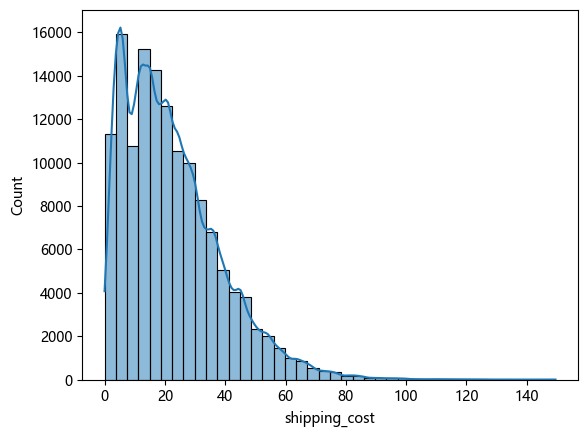

In [70]:
#61查看运费分布
ax = plt.subplot()
sns.histplot(data = df,
             x = 'shipping_cost',
             kde = True,
             bins = 40,
             ax = ax
            )
plt.show()
#可以看出，运费主要分布在0-40范围内，运费越高，订单越少。
#运费分布存在明显的波动，考虑与运费分档有关。
#分布存在长尾效应，考虑高运费与特殊运输需求有关，长途、偏远地区或特殊时段加急等。
#长尾效应可能使平均值失真。

In [76]:
#62对运费进行分区，查看各区内的成交情况
bins = [0, 30, 60, 90, 120, 150]
labels = ['<=30', '31-60', '61-90', '91-120', '121-150']
order_analysis['cost_bins'] = pd.cut(order_analysis['shipping_cost'], bins = bins, labels = labels)
return_ratio = order_analysis.groupby('cost_bins')['order_status'].apply(lambda x: x.isin(['Cancelled']).mean())

In [77]:
return_ratio = return_ratio.to_frame().reset_index()
return_ratio = return_ratio.rename(columns = {'order_status':'return_ratio'})

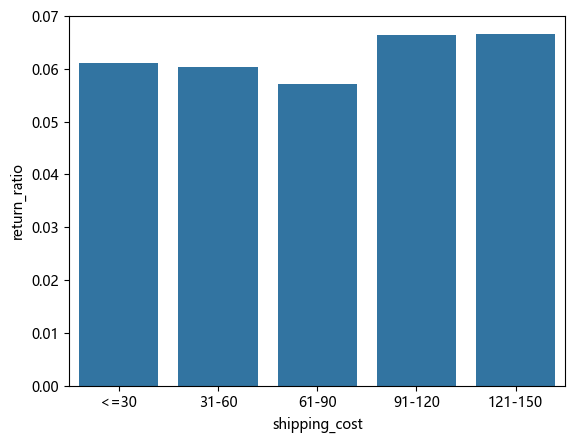

In [78]:
ax = plt.subplot()
sns.barplot(data = return_ratio,
              x = 'cost_bins',
              y = 'return_ratio',
              ax = ax
             )
plt.xlabel('shipping_cost')
plt.show()
#运费为60元以下时，订单取消率在6%左右，61-90元区间，取消率略有下降，91元以上取消率上升，约为6.5%左右。
#一般情况下，运输距离越远，运费越高，结合前面的分析，绝大部分订单的运费都在60元以内，60元以上可以认为是偏远地区发生的消费行为。
#通过下图可以初步判断，偏远地区对运费61-90元以内，接受度较高，运费高于90元时，取消订单的情况会增加。